# 11 Leakage check on G3

Step 18. Runs come from `python -m src.leakage` (logic in `src/leakage.py`), which logs every fold to `results/log.csv`. This notebook only reads the log.

LR and LightGBM on G3 with the settings chosen in Step 16 (notebooks 04 and 06), scored inside the train block under random stratified 5-fold, StratifiedGroupKFold on uid (5 folds) and the expanding time CV. The time-CV rows are the Step 16 tuning rows of the same settings. Every fold is fitted the same way: the pipeline is refit on the fold's training part, and LightGBM early-stops on the last 10% (by time) of that part, never on the rows it is scored on.

Random folds let a model see the same customers (and later months) in training, so they are expected to score highest.

In [1]:
import sys; sys.path.insert(0, '..')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src import leakage
from src.results import LOG_PATH
from src.data import ROOT

log = pd.read_csv(LOG_PATH)
# The test block was scored once, after the freeze (Step 19); this check reads only CV rows inside the train block.
cv_rows = log[log['cv_scheme'].isin(['random', 'group_uid', 'time'])]
assert (cv_rows['split'] == 'cv').all(), 'the leakage check must use train-block CV rows only'
best = leakage.chosen_settings(log)
table = leakage.leakage_table(log, best)
best

{'logreg': {'C': 0.03},
 'lgbm': {'learning_rate': 0.03,
  'min_child_samples': 300,
  'num_leaves': 127,
  'reg_lambda': 10.0,
  'scale_pos_weight': 1.0}}

## PR-AUC by model and CV scheme

In [2]:
pd.set_option('display.precision', 4)
table.pivot(index='model', columns='scheme', values='mean')[list(leakage.SCHEMES)]

scheme,random,group_uid,time
model,,,
lgbm,0.8408,0.6018,0.587
logreg,0.4417,0.4201,0.411


In [3]:
table.pivot(index='model', columns='scheme', values='std')[list(leakage.SCHEMES)]

scheme,random,group_uid,time
model,,,
lgbm,0.0103,0.0131,0.0256
logreg,0.0075,0.0117,0.0145


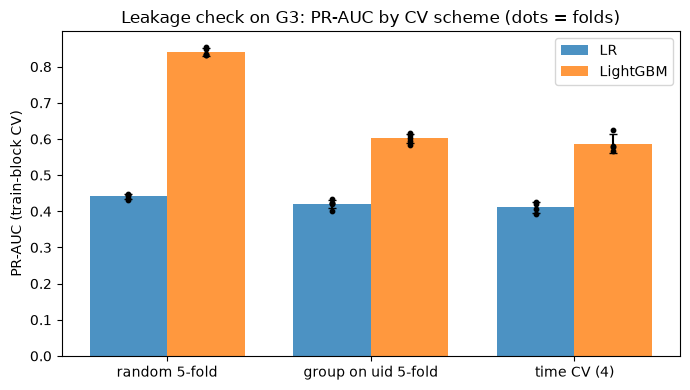

In [4]:
fig, ax = plt.subplots(figsize=(7, 4))
schemes = list(leakage.SCHEMES)
width = 0.38
for i, name in enumerate(leakage.MODELS):
    t = table[table.model == name].set_index('scheme').loc[schemes]
    x = np.arange(len(schemes)) + (i - 0.5) * width
    ax.bar(x, t['mean'], width, yerr=t['std'], capsize=3, alpha=0.8, label=leakage.NAMES[name])
    for xi, folds in zip(x, t['folds']):
        ax.scatter([xi] * len(folds), folds, s=10, color='black', zorder=3)
ax.set_xticks(range(len(schemes)), ['random 5-fold', 'group on uid 5-fold', 'time CV (4)'])
ax.set_ylabel('PR-AUC (train-block CV)')
ax.set_title('Leakage check on G3: PR-AUC by CV scheme (dots = folds)')
ax.legend(); fig.tight_layout()
fig.savefig(ROOT / 'reports' / 'figures' / 'leakage_check.png', dpi=150)

## Report text (as written to `reports/leakage_check.md`)

In [5]:
print(leakage.render(log, best))

# Leakage check on G3 (Step 18)

Generated by `.venv/bin/python -m src.leakage --report` from `results/log.csv`. Models use G3 and the settings chosen in Step 16 (LR {'C': 0.03}, LightGBM {'learning_rate': 0.03, 'min_child_samples': 300, 'num_leaves': 127, 'reg_lambda': 10.0, 'scale_pos_weight': 1.0}). All folds are inside the train block (first 472,432 rows); the validation and test blocks are not used. Every fold is fitted the same way: the preprocessing pipeline is refit on the fold's training part, and LightGBM trains on the first 90% of that part by time and early-stops on the last 10%, never on the rows it is scored on. Random and group folds use seed 0; time-CV rows are the Step 16 tuning rows of the same settings.

## PR-AUC by CV scheme (mean ± sample std over folds)

| Model | Random stratified 5-fold | StratifiedGroupKFold on uid (5) | Time CV (expanding, 4 folds) |
| --- | --- | --- | --- |
| LR | 0.4417 ± 0.0075 | 0.4201 ± 0.0117 | 0.4110 ± 0.0145 |
| LightGBM | 0.8408 ± 0